# Emotion Classification and VADER Sentiment Analysis

This project predicts six emotion labels from social-media text using **Logistic Regression**, **Linear Support Vector Classification**, and **Multinomial Naive Bayes**. It first evaluates TF-IDF baselines, then adds VADER-derived positive and negative sentiment channels and compares the same models under the same split and cross-validation procedure.

**Required split:** the first 4,000 rows train the models and the final 16,000 rows form a held-out test set. Model selection uses three-fold stratified cross-validation on the training set only. The test set is never used to select features or hyperparameters.

## 1. Imports and reproducibility

The notebook uses a fixed random seed. It saves all tables and figures to `outputs/` so results can be reviewed without rerunning every cell.

In [1]:
from pathlib import Path
import json, os, re, sys, warnings
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd().parent / ".matplotlib-cache"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_DIR / "data" / "DataSet - Complete.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
NLTK_DIR = PROJECT_DIR / "nltk_data"
OUTPUT_DIR.mkdir(exist_ok=True)
NLTK_DIR.mkdir(exist_ok=True)
nltk.data.path.insert(0, str(NLTK_DIR))
print(f"Python: {sys.version.split()[0]}")
print(f"Dataset: {DATA_PATH}")

Python: 3.9.10
Dataset: C:\Users\hoppe\Desktop\Machine_Learning_Project\data\DataSet - Complete.csv


## 2. Load and validate the dataset

The source CSV has no header, so names are assigned explicitly. Only a few shortened examples are displayed; the complete text collection is not printed.

In [2]:
label_names = {0: "sadness", 1: "joy", 2: "love", 3: "anger", 4: "fear", 5: "surprise"}
df = pd.read_csv(DATA_PATH, header=None, names=["id", "text", "label"])
df["text"] = df["text"].astype(str)
df["emotion"] = df["label"].map(label_names)

assert df.shape == (20000, 4), f"Unexpected shape: {df.shape}"
assert df["id"].is_unique, "IDs must be unique"
assert set(df["label"].unique()) == set(label_names), "Unexpected label values"
assert not df[["id", "text", "label"]].isna().any().any(), "Missing values found"

summary = pd.DataFrame({
    "rows": [len(df)], "unique_ids": [df.id.nunique()],
    "empty_texts": [(df.text.str.strip() == "").sum()],
    "duplicate_texts": [df.text.duplicated().sum()]
})
display(summary)
display(df.assign(text=df.text.str.slice(0, 90)).head(5))

,rows,unique_ids,empty_texts,duplicate_texts
0,20000,20000,0,54


,id,text,label,emotion
0,0,i just feel really helpless and heavy hearted,4,fear
1,1,ive enjoyed being able to slouch about relax a...,0,sadness
2,2,i gave up my internship with the dmrg and am f...,4,fear
3,3,i dont know i feel so lost,0,sadness
4,4,i am a kindergarten teacher and i am thoroughl...,4,fear


## 3. Exploratory data analysis

Class balance and text length matter because accuracy alone can hide weak performance on minority classes such as surprise.

,label,emotion,count,percent
0,0,sadness,5913,29.565
1,1,joy,6789,33.945
2,2,love,1605,8.025
3,3,anger,2721,13.605
4,4,fear,2233,11.165
5,5,surprise,739,3.695


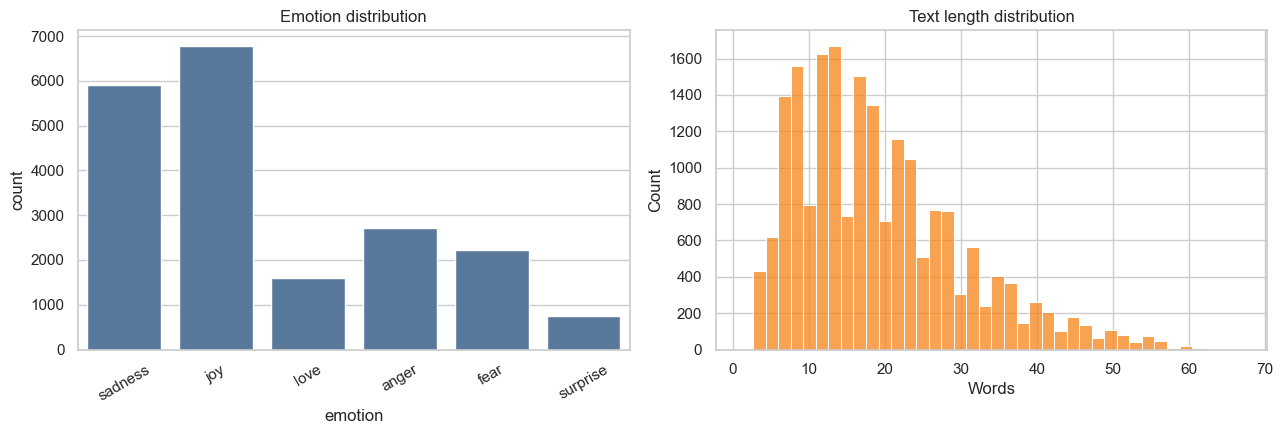

In [3]:
class_counts = (df.groupby(["label", "emotion"]).size().rename("count").reset_index())
class_counts["percent"] = 100 * class_counts["count"] / len(df)
display(class_counts)
class_counts.to_csv(OUTPUT_DIR / "class_distribution.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=class_counts, x="emotion", y="count", ax=axes[0], color="#4C78A8")
axes[0].set_title("Emotion distribution")
axes[0].tick_params(axis="x", rotation=30)
df["word_count"] = df.text.str.split().str.len()
sns.histplot(df["word_count"], bins=40, ax=axes[1], color="#F58518")
axes[1].set_title("Text length distribution")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Fixed 20%/80% split and leakage checks

Rows 0–3,999 are training data and rows 4,000–19,999 are held out for final testing. Three-fold stratification occurs only inside the training portion. Exact text overlap is reported because duplicates crossing the boundary could inflate test performance; the required split is preserved and any limitation is documented.

In [4]:
train_df = df.iloc[:4000].copy()
test_df = df.iloc[4000:].copy()
train_texts = set(train_df.text)
overlap_count = test_df.text.isin(train_texts).sum()
split_summary = pd.DataFrame({
    "partition": ["train", "test"], "rows": [len(train_df), len(test_df)],
    "first_id": [train_df.id.iloc[0], test_df.id.iloc[0]],
    "last_id": [train_df.id.iloc[-1], test_df.id.iloc[-1]]
})
display(split_summary)
print(f"Exact test texts also present in training: {overlap_count}")
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

,partition,rows,first_id,last_id
0,train,4000,0,3999
1,test,16000,4000,19999


Exact test texts also present in training: 20


## 5. VADER sentiment on original text

VADER is lexicon based and does not learn from the train or test labels. Its compound score ranges from −1 to +1. Standard thresholds classify scores below −0.05 as negative, above +0.05 as positive, and the remainder as neutral. We retain the untouched text for VADER.

In [5]:
try:
    nltk.data.find("sentiment/vader_lexicon.zip")
except LookupError:
    nltk.download("vader_lexicon", download_dir=str(NLTK_DIR), quiet=True)
sia = SentimentIntensityAnalyzer()
scores = df.text.map(sia.polarity_scores)
df["vader_compound"] = scores.map(lambda x: x["compound"])
df["sentiment_positive"] = df.vader_compound.clip(lower=0)
df["sentiment_negative"] = (-df.vader_compound).clip(lower=0)
df["sentiment_class"] = np.select(
    [df.vader_compound < -0.05, df.vader_compound > 0.05],
    ["negative", "positive"], default="neutral")
train_df = df.iloc[:4000].copy()
test_df = df.iloc[4000:].copy()
display(df[["emotion", "vader_compound", "sentiment_class"]].head())

,emotion,vader_compound,sentiment_class
0,fear,-0.5095,negative
1,sadness,0.6221,positive
2,fear,-0.4767,negative
3,sadness,-0.4572,negative
4,fear,-0.7590,negative


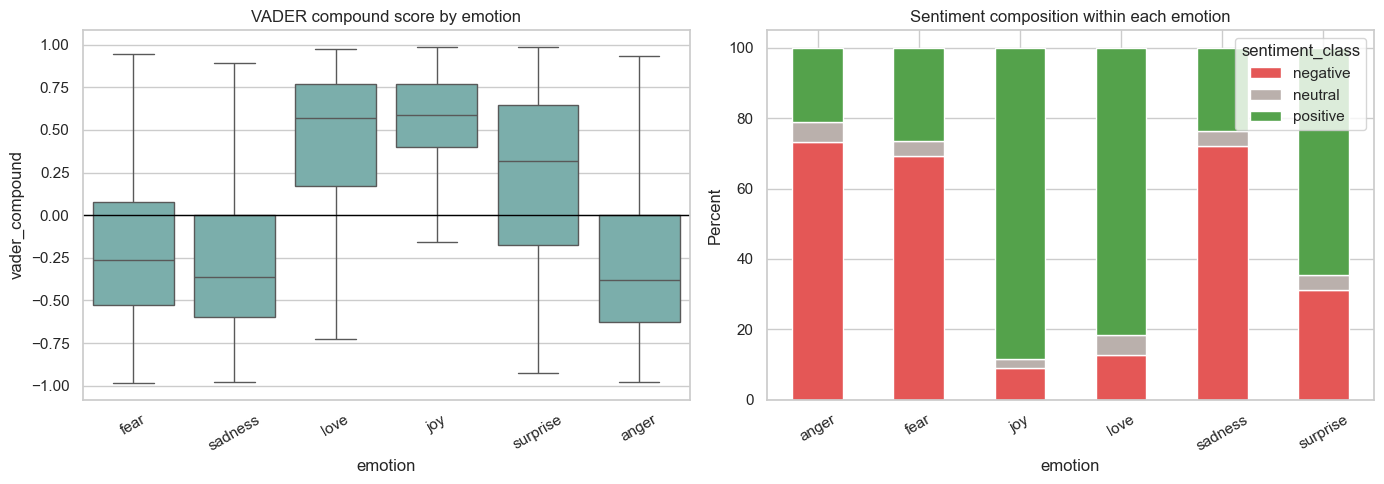

In [6]:
sentiment_table = pd.crosstab(df.emotion, df.sentiment_class)
sentiment_pct = pd.crosstab(df.emotion, df.sentiment_class, normalize="index") * 100
sentiment_table.to_csv(OUTPUT_DIR / "emotion_sentiment_counts.csv")
sentiment_pct.to_csv(OUTPUT_DIR / "emotion_sentiment_percent.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="emotion", y="vader_compound", ax=axes[0], color="#72B7B2", showfliers=False)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("VADER compound score by emotion")
axes[0].tick_params(axis="x", rotation=30)
sentiment_pct[["negative", "neutral", "positive"]].plot(
    kind="bar", stacked=True, ax=axes[1], color=["#E45756", "#BAB0AC", "#54A24B"])
axes[1].set_title("Sentiment composition within each emotion")
axes[1].set_ylabel("Percent")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "emotion_sentiment.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Model pipelines and training-only cross-validation

The TF-IDF vocabulary and inverse-document frequencies are fitted inside each cross-validation fold through a scikit-learn pipeline. This prevents validation or test text from influencing preprocessing. The augmented pipeline adds two nonnegative channels—positive magnitude and negative magnitude—derived from the compound score. Both stages use identical folds, model families, and parameter grids.

In [9]:
tfidf = TfidfVectorizer(
    lowercase=True, strip_accents="unicode", sublinear_tf=True,
    ngram_range=(1, 2), min_df=2, max_df=0.98, max_features=30000)

baseline_features = ColumnTransformer(
    [("tfidf", tfidf, "text")], remainder="drop")
augmented_features = ColumnTransformer([
    ("tfidf", tfidf, "text"),
    ("sentiment", "passthrough", ["sentiment_positive", "sentiment_negative"])
], remainder="drop")

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, solver="lbfgs", random_state=RANDOM_STATE),
        {"model__C": [0.5, 1.0, 2.0], "model__class_weight": [None, "balanced"]}),
    "Linear SVM": (
        LinearSVC(random_state=RANDOM_STATE),
        {"model__C": [0.5, 1.0, 2.0]}),
    "Multinomial NB": (
        MultinomialNB(),
        {"model__alpha": [0.1, 0.5, 1.0]})
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

In [10]:
def evaluate_stage(stage_name, feature_builder, train_frame, test_frame):
    rows, reports, matrices, searches = [], {}, {}, {}
    for model_name, (estimator, grid) in models.items():
        print(f"{stage_name}: {model_name}")
        pipeline = Pipeline([("features", feature_builder), ("model", estimator)])
        search = GridSearchCV(
            pipeline, grid, scoring="f1_macro", cv=cv, n_jobs=1,
            refit=True, return_train_score=False)
        search.fit(train_frame, train_frame.label)
        pred = search.predict(test_frame)
        precision, recall, f1_macro, _ = precision_recall_fscore_support(
            test_frame.label, pred, average="macro", zero_division=0)
        f1_weighted = precision_recall_fscore_support(
            test_frame.label, pred, average="weighted", zero_division=0)[2]
        rows.append({
            "stage": stage_name, "model": model_name,
            "cv_macro_f1": search.best_score_,
            "test_accuracy": accuracy_score(test_frame.label, pred),
            "test_macro_precision": precision, "test_macro_recall": recall,
            "test_macro_f1": f1_macro, "test_weighted_f1": f1_weighted,
            "best_parameters": json.dumps(search.best_params_, sort_keys=True)
        })
        reports[model_name] = classification_report(
            test_frame.label, pred, target_names=list(label_names.values()),
            output_dict=True, zero_division=0)
        matrices[model_name] = confusion_matrix(test_frame.label, pred)
        searches[model_name] = search
    return pd.DataFrame(rows), reports, matrices, searches

baseline_results, baseline_reports, baseline_cms, baseline_searches = evaluate_stage(
    "Baseline TF-IDF", baseline_features, train_df, test_df)
display(baseline_results)

Baseline TF-IDF: Logistic Regression
Baseline TF-IDF: Linear SVM
Baseline TF-IDF: Multinomial NB


,stage,model,cv_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,best_parameters
0,Baseline TF-IDF,Logistic Regression,0.683038,0.777687,0.751232,0.735957,0.743195,0.777211,"{""model__C"": 2.0, ""model__class_weight"": ""bala..."
1,Baseline TF-IDF,Linear SVM,0.718506,0.819688,0.815424,0.739714,0.770686,0.815762,"{""model__C"": 2.0}"
2,Baseline TF-IDF,Multinomial NB,0.485854,0.697063,0.769018,0.503549,0.534682,0.665645,"{""model__alpha"": 0.1}"


## 7. Baseline evaluation

Accuracy, macro precision, macro recall, macro F1, and weighted F1 provide complementary views. Macro F1 gives every emotion equal weight, making it especially important for this imbalanced dataset.

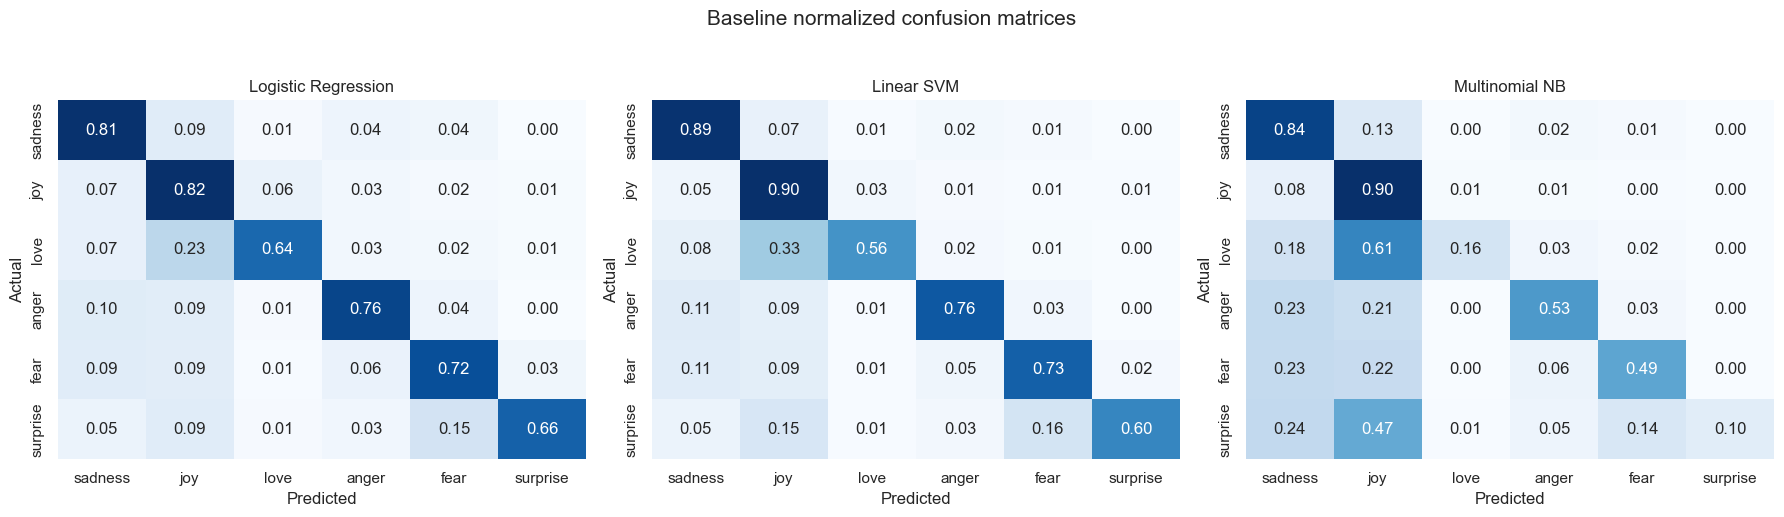

In [11]:
def save_reports(stage_slug, reports):
    for model_name, report in reports.items():
        pd.DataFrame(report).T.to_csv(
            OUTPUT_DIR / f"{stage_slug}_{model_name.lower().replace(' ', '_')}_report.csv")

def plot_confusions(cms, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (model_name, cm) in zip(axes, cms.items()):
        norm = cm / cm.sum(axis=1, keepdims=True)
        sns.heatmap(norm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
                    xticklabels=label_names.values(), yticklabels=label_names.values(), ax=ax)
        ax.set_title(model_name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    fig.suptitle(title, y=1.03, fontsize=15)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

save_reports("baseline", baseline_reports)
plot_confusions(baseline_cms, "Baseline normalized confusion matrices", "baseline_confusion_matrices.png")

## 8. Sentiment-augmented models

The supervised target remains the six-class emotion label. VADER contributes only the two extra sentiment magnitudes. Because Multinomial Naive Bayes requires nonnegative inputs, the signed compound score is represented as separate nonnegative positive and negative channels.

TF-IDF + VADER: Logistic Regression
TF-IDF + VADER: Linear SVM
TF-IDF + VADER: Multinomial NB


,stage,model,cv_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,best_parameters
0,TF-IDF + VADER,Logistic Regression,0.667218,0.758375,0.735332,0.701057,0.716509,0.756698,"{""model__C"": 2.0, ""model__class_weight"": ""bala..."
1,TF-IDF + VADER,Linear SVM,0.706901,0.810750,0.808543,0.723010,0.756491,0.805728,"{""model__C"": 2.0}"
2,TF-IDF + VADER,Multinomial NB,0.503289,0.718187,0.789000,0.519830,0.549927,0.686111,"{""model__alpha"": 0.1}"


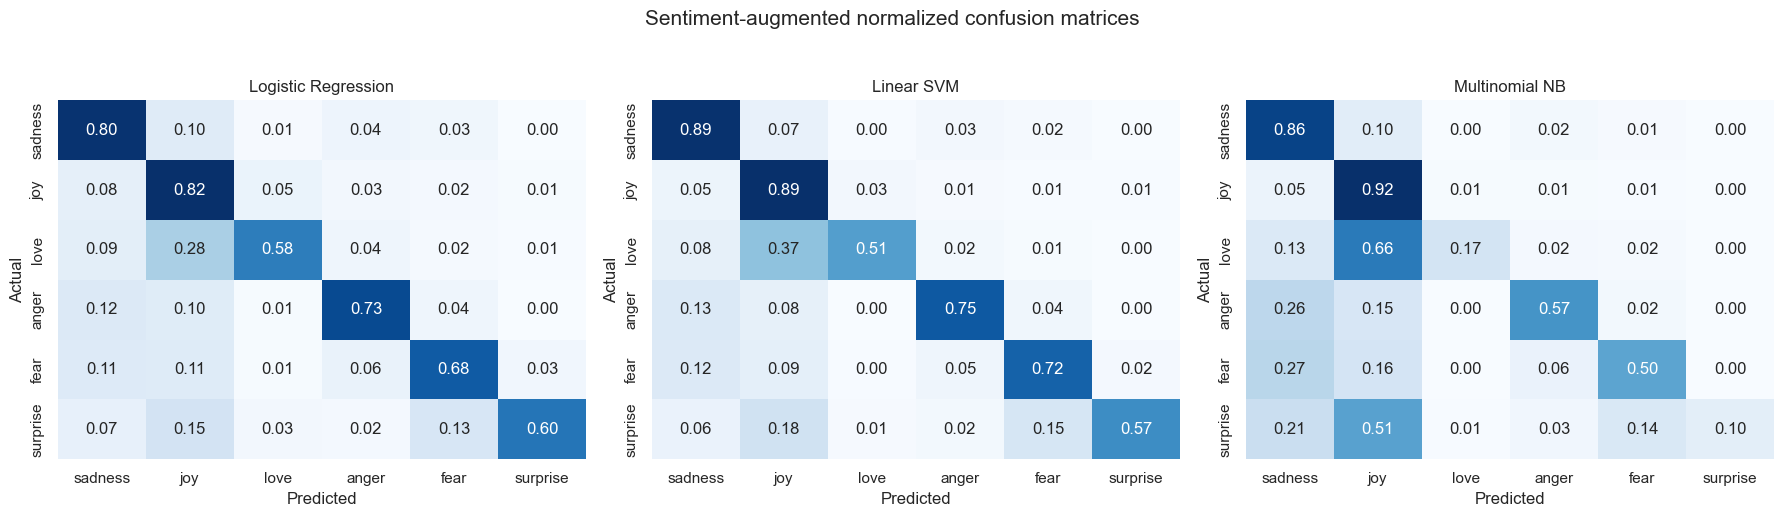

In [12]:
augmented_results, augmented_reports, augmented_cms, augmented_searches = evaluate_stage(
    "TF-IDF + VADER", augmented_features, train_df, test_df)
display(augmented_results)
save_reports("augmented", augmented_reports)
plot_confusions(augmented_cms, "Sentiment-augmented normalized confusion matrices",
                "augmented_confusion_matrices.png")

## 9. Fair before-and-after comparison

The comparison below uses the same training rows, held-out test rows, CV folds, TF-IDF configuration, hyperparameter grids, and metrics. Therefore the only systematic feature change is the addition of VADER sentiment channels.

test_accuracy                  test_macro_f1  \
stage               Baseline TF-IDF TF-IDF + VADER Baseline TF-IDF   
model                                                                
Linear SVM                   0.8197         0.8108          0.7707   
Logistic Regression          0.7777         0.7584          0.7432   
Multinomial NB               0.6971         0.7182          0.5347   

                                    
stage               TF-IDF + VADER  
model                               
Linear SVM                  0.7565  
Logistic Regression         0.7165  
Multinomial NB              0.5499

,model,test_accuracy_baseline,test_accuracy_augmented,accuracy_change,test_macro_f1_baseline,test_macro_f1_augmented,macro_f1_change
0,Logistic Regression,0.7777,0.7584,-0.0193,0.7432,0.7165,-0.0267
1,Linear SVM,0.8197,0.8108,-0.0089,0.7707,0.7565,-0.0142
2,Multinomial NB,0.6971,0.7182,0.0211,0.5347,0.5499,0.0152


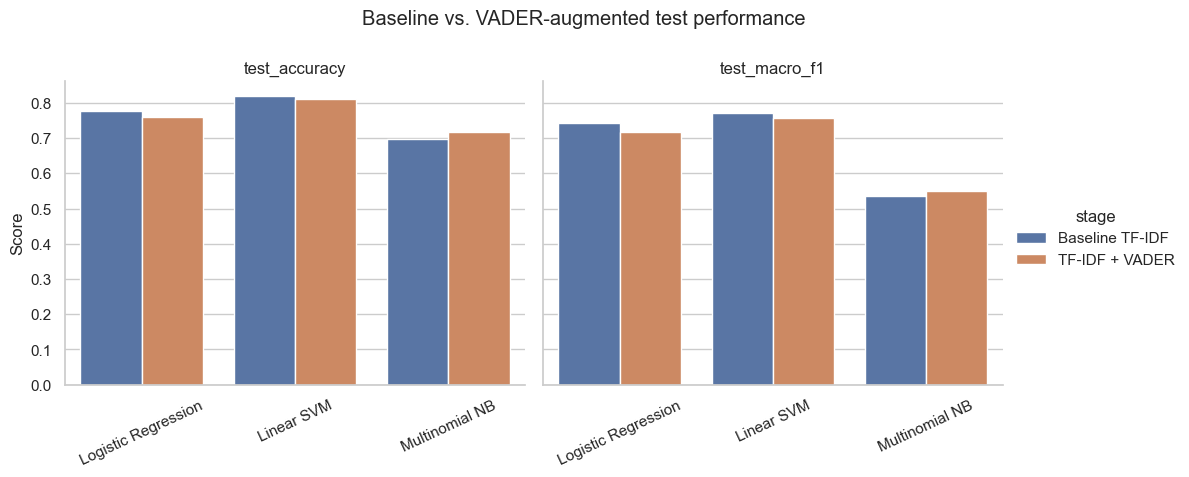

In [13]:
all_results = pd.concat([baseline_results, augmented_results], ignore_index=True)
all_results.to_csv(OUTPUT_DIR / "model_results.csv", index=False)
pivot = all_results.pivot(index="model", columns="stage", values=["test_accuracy", "test_macro_f1"])
display(pivot.round(4))

comparison = baseline_results.merge(augmented_results, on="model", suffixes=("_baseline", "_augmented"))
comparison["accuracy_change"] = comparison.test_accuracy_augmented - comparison.test_accuracy_baseline
comparison["macro_f1_change"] = comparison.test_macro_f1_augmented - comparison.test_macro_f1_baseline
comparison.to_csv(OUTPUT_DIR / "baseline_vs_augmented.csv", index=False)
display(comparison[["model", "test_accuracy_baseline", "test_accuracy_augmented",
                    "accuracy_change", "test_macro_f1_baseline", "test_macro_f1_augmented",
                    "macro_f1_change"]].round(4))

plot_data = all_results.melt(
    id_vars=["stage", "model"], value_vars=["test_accuracy", "test_macro_f1"],
    var_name="metric", value_name="score")
g = sns.catplot(data=plot_data, x="model", y="score", hue="stage", col="metric",
                kind="bar", height=4.5, aspect=1.15, sharey=True)
g.set_xticklabels(rotation=25)
g.set_axis_labels("", "Score")
g.set_titles("{col_name}")
g.figure.subplots_adjust(top=0.82)
g.figure.suptitle("Baseline vs. VADER-augmented test performance")
g.savefig(OUTPUT_DIR / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Conclusions and limitations

The executed tables above determine which model performs best and whether VADER improves each classifier. A small or negative change is still informative: VADER is a fixed general-purpose sentiment lexicon, whereas the target contains finer emotions that can share polarity (for example, anger and sadness are both often negative).

Important limitations:

- The required sequential 20%/80% split is intentionally unusual; it is not guaranteed to preserve the class distribution as cleanly as a randomized stratified split.
- Only 4,000 labeled rows train the models, including relatively few surprise examples.
- VADER sentiment is not ground truth sentiment and may misread slang, context, sarcasm, or domain-specific language.
- Hyperparameter search is deliberately modest for clarity and runtime.
- Exact train/test duplicate overlap, if reported above, can make evaluation optimistic.

A future robustness check could repeat the experiment with a randomized stratified split while clearly keeping it separate from the required primary experiment.